In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [2]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.keras'
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

# Set number of classes

In [3]:
NUM_CLASSES = 37

# Dataset reading

In [4]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [5]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input((21 * 2, )),

    tf.keras.layers.Dense(256, activation='relu',
                          kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128, activation='relu',
                          kernel_regularizer=tf.keras.regularizers.l2(0.0005)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [8]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │          11,008 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 37)                  │           2,405 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 56,357 (220.14 KB)

 Trainable params: 55,461 (216.64 KB)

 Non-trainable params: 896 (3.50 KB)

In [9]:
# Model checkpoint callback
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [10]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [11]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3025 - loss: 2.8064
Epoch 1: saving model to model/keypoint_classifier/keypoint_classifier.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.4948 - loss: 2.0667 - val_accuracy: 0.2307 - val_loss: 3.0756
Epoch 2/1000
72/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7959 - loss: 0.9967
Epoch 2: saving model to model/keypoint_classifier/keypoint_classifier.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8360 - loss: 0.8597 - val_accuracy: 0.2515 - val_loss: 2.7531
Epoch 3/1000
70/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9163 - loss: 0.5607
Epoch 3: saving model to model/keypoint_classifier/keypoint_classifier.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9260 - loss: 0.5102 - val_accuracy: 0.3832 - val_loss: 2.3641
Epoch 4/1000
69/73 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9494 - loss: 0.3876
Epoch 4: saving model to model/keypoint_classifier/keypoint_classifier.keras


In [12]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9968 - loss: 0.0591


In [13]:
# Loading the saved model
model = tf.keras.models.load_model(model_save_path)

In [14]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
[7.9722250e-11 7.4197554e-15 1.6344677e-11 6.1255006e-09 7.1891737e-10
 5.6142722e-09 3.6171281e-11 4.9905480e-14 7.8147810e-10 1.4147765e-10
 4.5524023e-15 1.0255573e-10 3.7296267e-08 7.1593656e-15 6.3658768e-14
 1.5238971e-13 1.7025929e-10 9.9077092e-12 5.7494440e-11 9.9621917e-15
 1.1033290e-13 1.1280880e-07 2.8125635e-07 2.5838541e-13 9.2032076e-12
 2.9874339e-08 6.6551537e-10 3.3079449e-14 4.3282294e-10 2.0601713e-15
 7.7480378e-10 1.1567367e-07 1.2042366e-11 9.9999940e-01 1.1135483e-14
 8.9243307e-11 1.4609313e-14]
33


# Confusion matrix

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


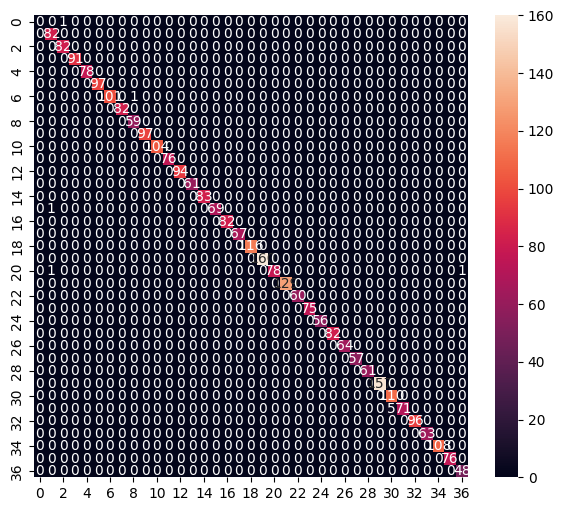

Classification Report
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.98      1.00      0.99        82
           2       0.99      1.00      0.99        82
           3       1.00      1.00      1.00        91
           4       1.00      1.00      1.00        78
           5       1.00      1.00      1.00        97
           6       1.00      0.99      1.00       102
           7       1.00      1.00      1.00        82
           8       0.98      1.00      0.99        59
           9       1.00      1.00      1.00        97
          10       1.00      1.00      1.00       104
          11       1.00      1.00      1.00        76
          12       1.00      1.00      1.00        94
          13       1.00      1.00      1.00        61
          14       1.00      1.00      1.00        83
          15       1.00      0.99      0.99        70
          16       1.00      1.00      1.00        82
     

C:\Users\swayam bhanvadiya\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\swayam bhanvadiya\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\swayam bhanvadiya\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

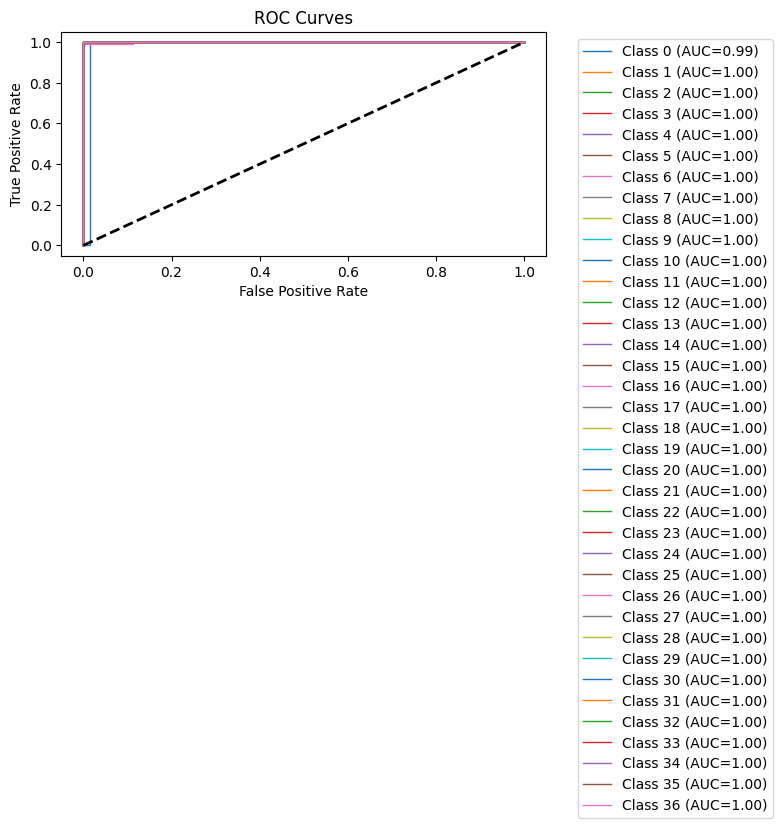

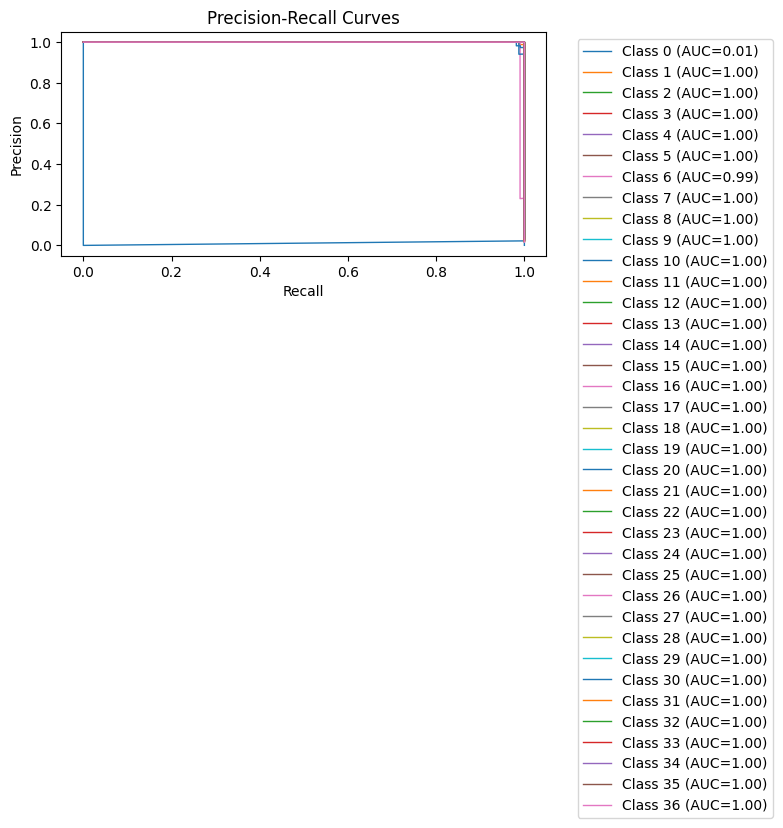

Log Loss: 0.0181
Matthews Correlation Coefficient: 0.9967
Cohen's Kappa: 0.9967


In [ ]:
# Additional evaluation metrics (ROC/AUC, Precision-Recall, Log Loss, MCC, Cohen's Kappa)
from sklearn.metrics import roc_curve, auc, precision_recall_curve, log_loss, matthews_corrcoef, cohen_kappa_score
from sklearn.preprocessing import label_binarize

labels = sorted(list(set(y_test)))
y_test_b = label_binarize(y_test, classes=labels)
y_score = Y_pred

# ROC AUC per class
fpr = {}
tpr = {}
roc_auc = {}
for i, lab in enumerate(labels):
    fpr[i], tpr[i], _ = roc_curve(y_test_b[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i, lab in enumerate(labels):
    plt.plot(fpr[i], tpr[i], lw=1, label=f"Class {lab} (AUC={roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Graph")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Precision-recall curves
precision = {}
recall = {}
pr_auc = {}
for i, lab in enumerate(labels):
    precision[i], recall[i], _ = precision_recall_curve(y_test_b[:, i], y_score[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i, lab in enumerate(labels):
    plt.plot(recall[i], precision[i], lw=1, label=f"Class {lab} (AUC={pr_auc[i]:.2f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Graph")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Scalar metrics
ll = log_loss(y_test, y_score)
mcc = matthews_corrcoef(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
print(f"Log Loss: {ll:.4f}")
print(f"Matthews Correlation Coefficient: {mcc:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")

# Convert to model for Tensorflow-Lite

In [17]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

In [18]:
# Transform model (quantization)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\SWAYAM~1\AppData\Local\Temp\tmp51pr86o2\assets


INFO:tensorflow:Assets written to: C:\Users\SWAYAM~1\AppData\Local\Temp\tmp51pr86o2\assets


Saved artifact at 'C:\Users\SWAYAM~1\AppData\Local\Temp\tmp51pr86o2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 37), dtype=tf.float32, name=None)
Captures:
  2591157381504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591120012416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591176013984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591176009232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591176010112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591176002368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591176002192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591202448432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591202451248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2591202449312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  25912024494

64744

# Inference test

In [19]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

C:\Users\swayam bhanvadiya\AppData\Local\Programs\Python\Python310\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [20]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [21]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [22]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 1e+03 μs


In [23]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[8.36577543e-11 8.12767754e-15 2.04292330e-11 7.50749773e-09
 6.58712251e-10 6.50948984e-09 3.26613285e-11 5.86837097e-14
 6.81856738e-10 1.53177637e-10 4.73553801e-15 1.05396074e-10
 3.90417512e-08 7.69184436e-15 6.65079970e-14 1.72293278e-13
 1.74044418e-10 1.01282611e-11 4.96434387e-11 1.13602670e-14
 1.22618482e-13 1.12390971e-07 2.34713610e-07 2.68353102e-13
 1.01816030e-11 3.11998463e-08 7.09231118e-10 3.75679644e-14
 4.02952394e-10 2.04719795e-15 8.54240456e-10 1.19018218e-07
 1.29654152e-11 9.99999523e-01 1.27290358e-14 8.04769654e-11
 1.67655112e-14]
33
